# Assignment 3: Understanding Customer Tipping Behavior

## Dataset description
The dataset contains information about restaurant bills and tips. Each row represents one dining group.

**Key variables:**
- `total_bill`: total cost of the meal
- `tip`: tip amount
- `sex`: gender of the person paying
- `smoker`: whether the group included smokers
- `day`: day of the week
- `time`: lunch or dinner
- `size`: group size

⚡💡 **Let's make it more interesting:**
You are a data analyst working for a restaurant chain. Management is curious about customer tipping behavior and wants data-driven insights:
- Do people tip more on weekends?
- Does gender or smoking status affect tips?
- How does the total bill influence tipping?

To answer these questions, you will analyze the famous Tips dataset from Seaborn and gradually clean, explore, and visualize the data until you reach a meaningful conclusion.

**Your task is to clean, explore, and visualize the data step by step, and then present meaningful conclusions based on your findings.**

## Q1: Loading and Understanding the Dataset (10 marks)
1. Load the `tips` dataset from seaborn.
2. Display the first 5 rows.
3. Print:
   - Dataset shape
   - Column names

In [59]:
#import lib
import seaborn as sns
import pandas as pd

In [61]:
#Q1.1: Load dataset
df = sns.load_dataset('tips')

In [67]:
#Q1.2: Display first rows
display(df.head())

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [11]:
#Q1.3: Dataset shape and columns
print("Dataset shape:", df.shape)
print("Column names:", list(df.columns))

Dataset shape: (244, 7)
Column names: ['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size']


## Q2: Basic Filtering – Who Tips More? (25 marks)
1. Filter only **weekend customers** (Saturday & Sunday). You may create two datasets, `weekend` and `weekdays`
2. Among them, find:
   - Average tip
   - Average total bill
3. Compare this with weekday customers.

In [69]:
#Q2.1: Weekend
weekend = df[df['day'].isin(['Sat', 'Sun'])]

In [71]:
# weekday
weekday = df[df['day'].isin(['Thur', 'Fri'])]

In [75]:
#Q2.2: Average tip, Average total bill
avg_tip_weekend = weekend['tip'].mean()
avg_tip_weekday = weekday['tip'].mean()

avg_bill_weekend = weekend['total_bill'].mean()
avg_bill_weekday = weekday['total_bill'].mean()

print("Выходные:\n", weekend[['tip', 'total_bill']].mean())
print("\nБудни:\n", weekday[['tip', 'total_bill']].mean())

Выходные:
 tip            3.115276
total_bill    20.893006
dtype: float64

Будни:
 tip            2.762840
total_bill    17.558148
dtype: float64


### Answer Q2.3: Compare this with weekday customers.

Weekend customers leave more tips and have a higher total bill than weekday customers. The average tip on weekends is $3.12, and the average total bill is $20.89. On weekdays, the average tip is $2.76, and the average total bill is $17.56.

## Q3: Sorting and Identifying High-Value Customers (15 marks)
1. Sort customers by `total_bill` (descending).
2. Display the **top 10 highest bills**.
3. What do you notice about their group sizes?

In [19]:
# Q3.1: Sort customers by total_bill (descending).
sorted_df = df.sort_values(by='total_bill', ascending=False)

In [27]:
# Q3.2: Display the top 10 highest bills.
top_10 = sorted_df.head(10)
display(top_10)

print("топ-10 size:")
print(top_10['size'].values)

,total_bill,tip,sex,smoker,day,time,size
170,50.81,10.00,Male,Yes,Sat,Dinner,3
212,48.33,9.00,Male,No,Sat,Dinner,4
59,48.27,6.73,Male,No,Sat,Dinner,4
156,48.17,5.00,Male,No,Sun,Dinner,6
182,45.35,3.50,Male,Yes,Sun,Dinner,3
102,44.30,2.50,Female,Yes,Sat,Dinner,3
197,43.11,5.00,Female,Yes,Thur,Lunch,4
142,41.19,5.00,Male,No,Thur,Lunch,5
184,40.55,3.00,Male,Yes,Sun,Dinner,2
95,40.17,4.73,Male,Yes,Fri,Dinner,4


топ-10:
[3 4 4 6 3 3 4 5 2 4]


### Answer Q3.3: What do you notice about their group sizes?
The group sizes for the highest bills are mostly 3, 4, or 5 people. This shows that larger groups usually spend more money and have higher total bills.

## Q4: Data Quality Check & Cleaning (10 marks)
1. Check if the dataset has missing values.
2. **Why missing values are dangerous** in machine learning.

In [37]:
#Q4.1: missing values
missing_values = df.isnull().sum()
print(missing_values)

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64


### Answer Q4.2: Why missing values are dangerous in machine learning.

Missing values are dangerous in machine learning because many algorithms cannot work with empty data and will give errors. Also, they can make the model less accurate and give wrong predictions.

## Q5: Visualization – What Influences Tips? (25 marks)
1. Plot:
   - Tip vs Total Bill (scatter plot)
   - Average tip by day (bar plot)
   - Tip distribution (histogram)
2. Interpret each plot in 1–2 sentences.

Text(0.5, 1.0, 'Tip vs Total Bill')

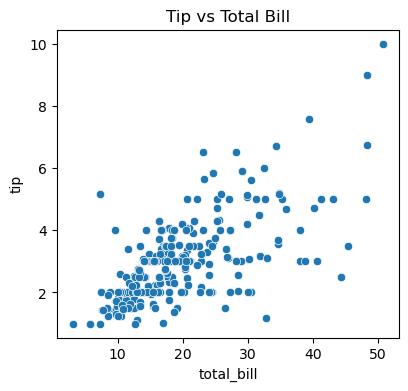

In [39]:
#Q5.1: Tip vs Total Bill (scatter plot)

import matplotlib.pyplot as plt

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.scatterplot(data=df, x='total_bill', y='tip')
plt.title('Tip vs Total Bill')

Text(0.5, 1.0, 'Average Tip by Day')

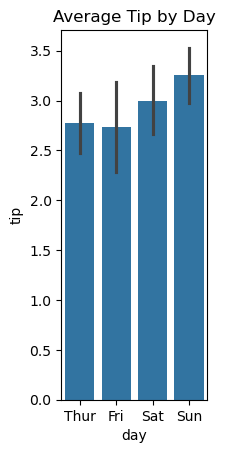

In [41]:
# Q5.1: Average tip by day (bar plot)
plt.subplot(1, 3, 2)
sns.barplot(data=df, x='day', y='tip', estimator='mean')
plt.title('Average Tip by Day')

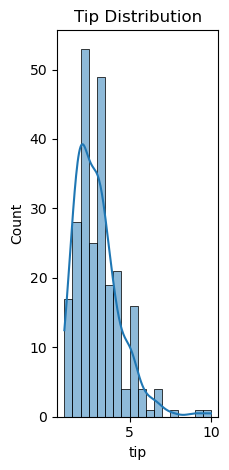

In [43]:
# Q5.1: Tip distribution (histogram)
plt.subplot(1, 3, 3)
sns.histplot(df['tip'], kde=True)
plt.title('Tip Distribution')

plt.tight_layout()
plt.show()

### Answer Q5.2: Interpret each plot in 1–2 sentences.

Tip vs Total Bill: The scatter plot shows a positive relationship between the total bill and tips. This means that as the total bill increases, the tips usually increase too.   
Average Tip by Day: The bar plot shows that average tips are highest on weekends, especially on Sundays. Customers leave slightly smaller average tips on Thursdays and Fridays.   
Tip Distribution: The histogram shows that most tips are between $2 and $4. The data is skewed to the right, which means very high tips are rare. 

## Q6: Final Insight & Conclusion (25 marks)
In 6–8 sentences, summarize:
- Who tips more?
- When tips are highest?
- How this insight could help restaurant management.

### Answer Q6:

`Customers` -- Customers with larger total bills and groups usually leave higher tips. Tips and total bills are highest on weekends, especially on Saturdays and Sundays. Most customers give standard tips between $2 and $4. 

`Restaurant managers` -- Restaurant managers can use this information to improve their business. They should schedule more staff and workers for the weekend shifts. Managers can also train waiters to give better service to larger groups. This will help increase the restaurant's total revenue and staff tips.